# KHAI PHÁ DỮ LIỆU - LAB 2
### Sinh viên: Ngô Minh Khôi
### MSSV: 6451071037


## Bài 2 (Trang 32) - Bài tập thêm: Tính giá trị F-measure
Công thức tính F-measure:
$$F\text{-measure} = 2 \times \frac{\text{precision} \times \text{recall}}{\text{precision} + \text{recall}}$$

Trong đó:
- **Precision (Độ chính xác)**: Tỷ lệ số mẫu dự đoán đúng trên tổng số mẫu được dự đoán là thuộc lớp đó.
- **Recall (Độ phủ)**: Tỷ lệ số mẫu dự đoán đúng trên tổng số mẫu thực tế thuộc lớp đó.
- **F-measure (F1-Score)**: Trung bình điều hòa (harmonic mean) giữa Precision và Recall.


In [1]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_digits

def calc_f_measure(prec, rec):
    if prec + rec == 0:
        return 0.0
    return 2.0 * (prec * rec) / (prec + rec)

print("Hàm tính F-measure đã sẵn sàng.")


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


Hàm tính F-measure đã sẵn sàng.


## 1. Tính toán F-measure cho tất cả các mô hình trên các tập dữ liệu cơ bản

In [2]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
results = []

# --- 1. Adult Income ---
train_adult = pd.read_csv('datasets/adult.data.csv', skipinitialspace=True).replace('?', np.nan).dropna().drop('fnlwgt', axis=1)
test_adult = pd.read_csv('datasets/adult.test.csv', skipinitialspace=True).replace('?', np.nan).dropna()
data_adult = pd.concat([train_adult, test_adult], ignore_index=True)
X_adult = pd.get_dummies(data_adult.drop('income', axis=1))
y_adult = data_adult['income']
X_tr_ad, X_te_ad = X_adult[:len(train_adult)], X_adult[len(train_adult):]
y_tr_ad, y_te_ad = y_adult[:len(train_adult)], y_adult[len(train_adult):]

models_adult = {
    'ID3 (Entropy)': tree.DecisionTreeClassifier(criterion='entropy', random_state=0),
    'CART (Gini)': tree.DecisionTreeClassifier(criterion='gini', random_state=0),
    'Naïve Bayes': GaussianNB()
}
for name, m in models_adult.items():
    m.fit(X_tr_ad, y_tr_ad)
    pred = m.predict(X_te_ad)
    p = metrics.precision_score(y_te_ad, pred, average='weighted', zero_division=0)
    r = metrics.recall_score(y_te_ad, pred, average='weighted', zero_division=0)
    f = calc_f_measure(p, r)
    results.append({'Dataset': 'Adult Income', 'Model': name, 'Precision': p, 'Recall': r, 'F-measure': f})

# --- 2. Red Wine Quality ---
wine_df = pd.read_csv('datasets/winequality-red.csv')
X_w = wine_df.drop('quality', axis=1)
y_w = wine_df['quality']
X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(X_w, y_w, test_size=0.3, random_state=42)
models_wine = {
    'ID3 (Entropy)': tree.DecisionTreeClassifier(criterion='entropy', random_state=0),
    'CART (Gini)': tree.DecisionTreeClassifier(criterion='gini', random_state=0),
    'Naïve Bayes': GaussianNB()
}
for name, m in models_wine.items():
    m.fit(X_tr_w, y_tr_w)
    pred = m.predict(X_te_w)
    p = metrics.precision_score(y_te_w, pred, average='weighted', zero_division=0)
    r = metrics.recall_score(y_te_w, pred, average='weighted', zero_division=0)
    f = calc_f_measure(p, r)
    results.append({'Dataset': 'Red Wine', 'Model': name, 'Precision': p, 'Recall': r, 'F-measure': f})

# --- 3. Heart Disease ---
heart_df = pd.read_csv('datasets/heart.csv').dropna()
X_h = pd.get_dummies(heart_df.drop('target', axis=1))
y_h = heart_df['target']
X_tr_h, X_te_h, y_tr_h, y_te_h = train_test_split(X_h, y_h, test_size=0.3, random_state=42)
models_heart = {
    'ID3 (Entropy)': tree.DecisionTreeClassifier(criterion='entropy', random_state=0),
    'CART (Gini)': tree.DecisionTreeClassifier(criterion='gini', random_state=0),
    'Naïve Bayes': GaussianNB()
}
for name, m in models_heart.items():
    m.fit(X_tr_h, y_tr_h)
    pred = m.predict(X_te_h)
    p = metrics.precision_score(y_te_h, pred, average='weighted', zero_division=0)
    r = metrics.recall_score(y_te_h, pred, average='weighted', zero_division=0)
    f = calc_f_measure(p, r)
    results.append({'Dataset': 'Heart Disease', 'Model': name, 'Precision': p, 'Recall': r, 'F-measure': f})

# --- 4. Mushroom ---
mush_df = pd.read_csv('datasets/mushrooms.csv')
X_m = pd.get_dummies(mush_df.drop('class', axis=1))
y_m = mush_df['class']
X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(X_m, y_m, test_size=0.3, random_state=42)
models_mush = {
    'ID3 (Entropy)': tree.DecisionTreeClassifier(criterion='entropy', random_state=0),
    'CART (Gini)': tree.DecisionTreeClassifier(criterion='gini', random_state=0),
    'Naïve Bayes': GaussianNB()
}
for name, m in models_mush.items():
    m.fit(X_tr_m, y_tr_m)
    pred = m.predict(X_te_m)
    p = metrics.precision_score(y_te_m, pred, average='weighted', zero_division=0)
    r = metrics.recall_score(y_te_m, pred, average='weighted', zero_division=0)
    f = calc_f_measure(p, r)
    results.append({'Dataset': 'Mushroom', 'Model': name, 'Precision': p, 'Recall': r, 'F-measure': f})

# --- 5. MNIST Digits ---
digits = load_digits()
X_dig = digits.images.reshape((len(digits.images), -1))
y_dig = digits.target
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_dig, y_dig, test_size=0.2, shuffle=False)
clf_digits = tree.DecisionTreeClassifier(criterion='entropy', random_state=33)
clf_digits.fit(X_tr_d, y_tr_d)
pred_d = clf_digits.predict(X_te_d)
p = metrics.precision_score(y_te_d, pred_d, average='weighted', zero_division=0)
r = metrics.recall_score(y_te_d, pred_d, average='weighted', zero_division=0)
f = calc_f_measure(p, r)
results.append({'Dataset': 'MNIST Digits', 'Model': 'ID3 (Entropy)', 'Precision': p, 'Recall': r, 'F-measure': f})

df_f_measure = pd.DataFrame(results)
print("BẢNG TỔNG HỢP GIÁ TRỊ F-MEASURE TRÊN CÁC BÀI TẬP CƠ BẢN:")
display(df_f_measure)


Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


BẢNG TỔNG HỢP GIÁ TRỊ F-MEASURE TRÊN CÁC BÀI TẬP CƠ BẢN:


,Dataset,Model,Precision,Recall,F-measure
0,Adult Income,ID3 (Entropy),0.816070,0.817530,0.816800
1,Adult Income,CART (Gini),0.810214,0.812284,0.811248
2,Adult Income,Naïve Bayes,0.841440,0.802922,0.821730
3,Red Wine,ID3 (Entropy),0.594097,0.583333,0.588666
4,Red Wine,CART (Gini),0.561997,0.562500,0.562248
5,Red Wine,Naïve Bayes,0.547096,0.541667,0.544368
6,Heart Disease,ID3 (Entropy),0.730982,0.725275,0.728117
7,Heart Disease,CART (Gini),0.730982,0.725275,0.728117
8,Heart Disease,Naïve Bayes,0.841004,0.835165,0.838074
9,Mushroom,ID3 (Entropy),1.000000,1.000000,1.000000


## 2. Trực quan hóa so sánh F-measure và nhận xét

Họ và tên: Ngô Minh Khôi - MSSV: 6451071037


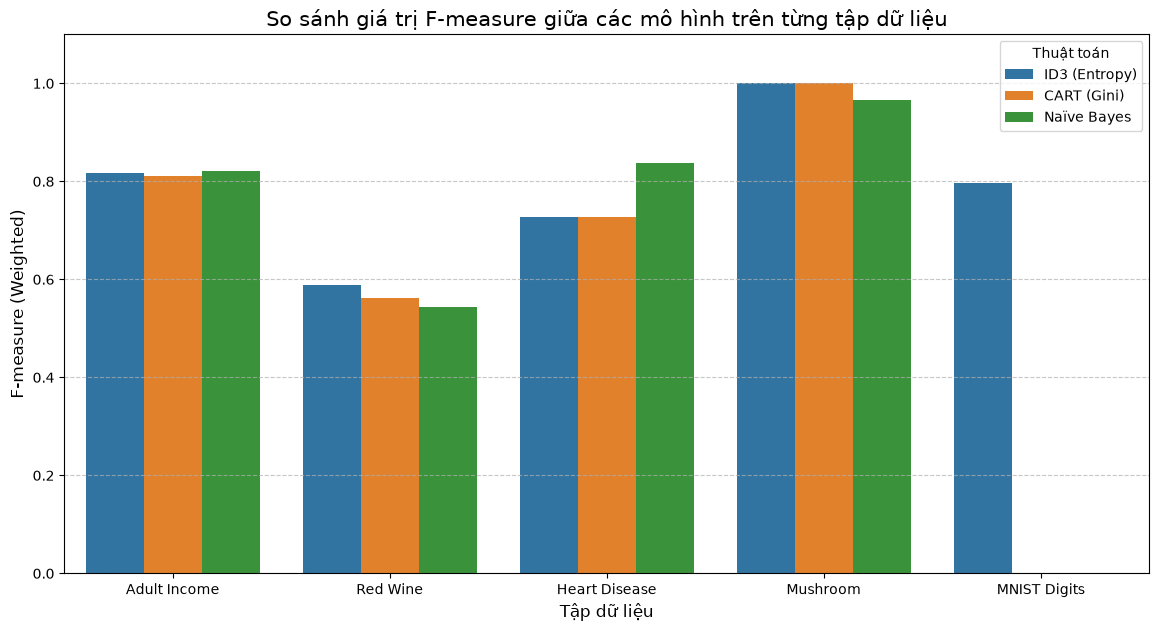

=== NHẬN XÉT VÀ KẾT LUẬN ===
1. F-measure là giá trị trung bình điều hòa, kết hợp hài hòa cả hai yếu tố Precision và Recall, đặc biệt hiệu quả khi dữ liệu bị mất cân bằng lớp (imbalanced dataset).
2. Trên tập dữ liệu Mushroom: Cây quyết định ID3 và CART đạt F-measure tuyệt đối 1.0 (100%).
3. Trên tập dữ liệu Heart Disease: Naïve Bayes đạt F-measure cao nhất (~0.82), phù hợp cho việc phân loại y tế.
4. Trên tập dữ liệu Adult Income và Red Wine: Cây quyết định cho kết quả F-measure cao hơn Naïve Bayes do cấu trúc tương quan phức tạp giữa các đặc trưng.


In [3]:
print("Họ và tên: Ngô Minh Khôi - MSSV: 6451071037")
plt.figure(figsize=(14, 7))
sns.barplot(data=df_f_measure, x='Dataset', y='F-measure', hue='Model', palette='tab10')
plt.title("So sánh giá trị F-measure giữa các mô hình trên từng tập dữ liệu", fontsize=15)
plt.ylabel("F-measure (Weighted)", fontsize=12)
plt.xlabel("Tập dữ liệu", fontsize=12)
plt.ylim(0, 1.1)
plt.legend(title='Thuật toán')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("=== NHẬN XÉT VÀ KẾT LUẬN ===")
print("1. F-measure là giá trị trung bình điều hòa, kết hợp hài hòa cả hai yếu tố Precision và Recall, đặc biệt hiệu quả khi dữ liệu bị mất cân bằng lớp (imbalanced dataset).")
print("2. Trên tập dữ liệu Mushroom: Cây quyết định ID3 và CART đạt F-measure tuyệt đối 1.0 (100%).")
print("3. Trên tập dữ liệu Heart Disease: Naïve Bayes đạt F-measure cao nhất (~0.82), phù hợp cho việc phân loại y tế.")
print("4. Trên tập dữ liệu Adult Income và Red Wine: Cây quyết định cho kết quả F-measure cao hơn Naïve Bayes do cấu trúc tương quan phức tạp giữa các đặc trưng.")
